# Actividad Integradora · Tarea 2
## Red Neuronal Artificial para clasificación binaria con Keras
**Fundamentos de Machine Learning I · Maestría en Ciencia de Datos · Universidad DaVinci**
Autor: Fredys Agustin Caballero Soto

---
### Objetivo
Construir, entrenar y evaluar una red neuronal artificial (RNA) que clasifique **tumores de mama como malignos o benignos** a partir de 30 medidas numéricas, usando Python, Scikit-Learn y TensorFlow/Keras.

### Cómo está organizado este cuaderno
Sigue **los 6 pasos del enunciado**, en el mismo orden. Cada paso tiene: (1) qué vamos a hacer y por qué, (2) el código comentado y (3) cómo leer el resultado.

| Paso | Qué se hace |
|---|---|
| 1 | Seleccionar un conjunto de datos adecuado para clasificación binaria |
| 2 | Importar bibliotecas y cargar el dataset |
| 3 | Preprocesar: dividir 80/20 y escalar con `StandardScaler` |
| 4 | Construir la red (`Sequential` + `Dense`), compilar (`adam`, `binary_crossentropy`) y entrenar 50 épocas con 10 % de validación |
| 5 | Evaluar con el conjunto de prueba: *loss* y *accuracy* |
| 6 | Visualizar la historia del entrenamiento con `matplotlib` |

> **Cómo ejecutarlo:** menú *Entorno de ejecución → Ejecutar todo*. Google Colab ya trae TensorFlow, NumPy, Pandas, Scikit-Learn y Matplotlib instalados.

---
## Paso 1 · Seleccionar un conjunto de datos

**Qué pide el enunciado:** un dataset (Kaggle, UCI, etc.) adecuado para **clasificación binaria**, es decir, donde la variable objetivo tenga solo dos categorías.

**Dataset elegido: Breast Cancer Wisconsin (Diagnostic)**, del repositorio UCI Machine Learning Repository, que viene incluido en Scikit-Learn.

| Característica | Valor |
|---|---|
| Registros | 569 pacientes |
| Variables de entrada | 30 numéricas (radio, textura, perímetro, área, suavidad, etc. del núcleo celular: media, error estándar y peor valor) |
| Variable objetivo | `target`: **0 = maligno**, **1 = benigno** |
| Valores nulos | Ninguno |

**¿Por qué es una buena elección?**
- Es **binaria** por naturaleza (maligno / benigno), tal como pide la tarea.
- Todas las variables son **numéricas**, así que no hace falta codificar categorías y podemos concentrarnos en la red neuronal.
- Es un caso real de **diagnóstico de enfermedades**, uno de los ejemplos que menciona el enunciado.
- Es pequeño: entrena en segundos, ideal para Colab.

**Fuente:** Wolberg, W. H., Street, W. N., & Mangasarian, O. L. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17

---
## Paso 2 · Importar las bibliotecas y cargar el dataset

**Qué pide el enunciado:** importar NumPy, Pandas, Scikit-Learn y TensorFlow/Keras, cargar el dataset y prepararlo.

**Para qué sirve cada biblioteca:**
- `numpy`: operaciones con arreglos numéricos (la red trabaja con ellos).
- `pandas`: tablas (`DataFrame`) para explorar los datos.
- `sklearn`: carga del dataset, división train/test, escalado y métricas.
- `tensorflow.keras`: construcción y entrenamiento de la red.
- `matplotlib`: gráficas (Paso 6).

Fijamos una **semilla aleatoria** (`42`) para que los resultados sean **reproducibles**: si otra persona ejecuta el cuaderno, obtendrá resultados muy parecidos.

In [1]:
# --- Bibliotecas ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

# --- Reproducibilidad ---
SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)   # fija semillas de Python, NumPy y TensorFlow
tf.config.experimental.enable_op_determinism()  # operaciones deterministas

print("TensorFlow:", tf.__version__)

I0000 00:00:1791508287.958698    4293 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0


### Cargar los datos y explorarlos
Cargamos el dataset como `DataFrame` (`as_frame=True`) y revisamos tres cosas antes de modelar: **tamaño**, **valores nulos** y **balance de clases**. Un dataset muy desbalanceado haría que la *accuracy* engañe.

In [2]:
datos = load_breast_cancer(as_frame=True)
df = datos.frame                      # 30 variables + columna 'target'

print("Filas y columnas:", df.shape)
print("Valores nulos en total:", int(df.isna().sum().sum()))
print()
print("Variable objetivo: 0 = maligno, 1 = benigno")
print(df["target"].value_counts().rename({0: "maligno (0)", 1: "benigno (1)"}))
df.head()

Filas y columnas: (569, 31)
Valores nulos en total: 0

Variable objetivo: 0 = maligno, 1 = benigno
target
benigno (1)    357
maligno (0)    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Cómo leer el resultado:** hay 569 filas y 31 columnas (30 variables de entrada + `target`), **ningún nulo**, y 357 benignos frente a 212 malignos (≈ 63 % / 37 %). Hay algo de desbalance, pero moderado: por eso más adelante, además de la *accuracy*, miramos la matriz de confusión.

Separamos ahora las **entradas (X)** de la **etiqueta (y)**:

In [3]:
X = df.drop(columns="target")   # 30 variables de entrada
y = df["target"]                # 0 = maligno, 1 = benigno
print("X:", X.shape, "| y:", y.shape)

X: (569, 30) | y: (569,)


---
## Paso 3 · Preprocesar los datos

**Qué pide el enunciado:** (a) escalar con `StandardScaler`, (b) dividir en 80 % entrenamiento y 20 % prueba.

### ¿Por qué escalar?
Las variables están en escalas muy distintas: el *área* ronda los cientos y la *suavidad*, las décimas. Una red neuronal aprende con descenso de gradiente, y con escalas tan dispares el entrenamiento se vuelve lento e inestable. `StandardScaler` transforma cada variable para que tenga **media 0 y desviación estándar 1**:

$$z = \frac{x - \mu}{\sigma}$$

### ¿Por qué dividir *antes* de escalar? (fuga de datos)
Aunque el enunciado lista primero el escalado, el orden correcto es **dividir primero y escalar después**:
1. Se divide en train/test.
2. El `StandardScaler` se **ajusta (`fit`) solo con el conjunto de entrenamiento** (calcula μ y σ ahí).
3. Con esos mismos μ y σ se **transforma (`transform`) el conjunto de prueba**.

Si calculáramos μ y σ con todos los datos, el conjunto de prueba "filtraría" información al entrenamiento (*data leakage*) y la evaluación saldría más optimista de lo real. En un proyecto de BI sería como calcular el promedio de un KPI usando datos del futuro.

### Detalles de la división
- `test_size=0.2` → 80 % entrenamiento / 20 % prueba.
- `stratify=y` → mantiene la **misma proporción de malignos y benignos** en ambos conjuntos.
- `random_state=42` → la división es reproducible.

In [4]:
# 1) División 80 % / 20 % (estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)
print(f"Entrenamiento: {X_train.shape[0]} filas | Prueba: {X_test.shape[0]} filas")
print("Proporción de benignos  -> train: {:.3f} | test: {:.3f}".format(y_train.mean(), y_test.mean()))

# 2) Escalado: fit SOLO con train, transform en ambos
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# 3) Verificación: en train la media debe ser ~0 y la desviación ~1
print("\nTrain  -> media promedio: {:.4f} | desviación promedio: {:.4f}".format(X_train.mean(), X_train.std()))
print("Prueba -> media promedio: {:.4f} | desviación promedio: {:.4f}".format(X_test.mean(), X_test.std()))

Entrenamiento: 455 filas | Prueba: 114 filas
Proporción de benignos  -> train: 0.626 | test: 0.632

Train  -> media promedio: -0.0000 | desviación promedio: 1.0000
Prueba -> media promedio: 0.0296 | desviación promedio: 0.9626


**Cómo leer el resultado:** 455 filas para entrenar y 114 para probar, con la misma proporción de clases en ambos. En entrenamiento la media es ≈ 0 y la desviación ≈ 1 (el escalado funcionó). En prueba los valores se **parecen** pero no son exactamente 0 y 1: es lo esperado y correcto, porque se escaló con los parámetros del entrenamiento.

---
## Paso 4 · Construir, compilar y entrenar la red neuronal

### 4.1 Construir el modelo (`Sequential` + `Dense`)
`Sequential` apila capas una tras otra: la salida de una es la entrada de la siguiente. Cada capa `Dense` es **totalmente conectada**: todas sus neuronas reciben todas las salidas de la capa anterior.

Arquitectura elegida:

| Capa | Neuronas | Activación | Función |
|---|---|---|---|
| Entrada | 30 | — | Una neurona por variable de entrada |
| Oculta 1 | 16 | ReLU | Aprende combinaciones de las variables |
| Oculta 2 | 8 | ReLU | Refina esas combinaciones |
| Salida | 1 | Sigmoide | Entrega una probabilidad entre 0 y 1 |

- **ReLU** (`max(0, x)`) en las ocultas: simple, rápida y evita que el gradiente se desvanezca.
- **Sigmoide** en la salida: comprime el resultado a (0, 1), interpretable como *probabilidad de que el tumor sea benigno*. Si es ≥ 0,5 se clasifica como benigno (1); si no, maligno (0). Es lo estándar en clasificación **binaria**.
- Una red pequeña es suficiente: tenemos solo 455 ejemplos, y una red grande tendería al **sobreajuste** (memorizar en vez de generalizar).

In [5]:
modelo = Sequential([
    Input(shape=(X_train.shape[1],)),        # 30 variables de entrada
    Dense(16, activation="relu"),            # capa oculta 1
    Dense(8,  activation="relu"),            # capa oculta 2
    Dense(1,  activation="sigmoid"),         # salida: probabilidad de 'benigno'
])

modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

**Cómo leer el resumen:** los parámetros son los **pesos y sesgos** que la red debe aprender.
- Oculta 1: 30 × 16 pesos + 16 sesgos = **496**
- Oculta 2: 16 × 8 + 8 = **136**
- Salida: 8 × 1 + 1 = **9**
- Total: **641 parámetros**, muy pocos frente a las 455 filas × 30 variables de datos disponibles.

### 4.2 Compilar el modelo
Compilar es decirle a Keras **cómo va a aprender**:
- **Optimizador `adam`:** el algoritmo que ajusta los pesos. Adapta la tasa de aprendizaje de cada peso automáticamente; es una opción robusta por defecto.
- **Pérdida `binary_crossentropy`:** mide qué tan mal están las probabilidades predichas. Penaliza mucho estar muy seguro y equivocarse. Es la pérdida estándar para clasificación binaria con salida sigmoide.
- **Métrica `accuracy`:** proporción de aciertos. No influye en el aprendizaje; solo la reportamos para entender el desempeño.

In [6]:
modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
print("Modelo compilado.")

Modelo compilado.


### 4.3 Entrenar: 50 épocas con 10 % de validación
- **`epochs=50`:** la red recorre 50 veces todo el conjunto de entrenamiento.
- **`validation_split=0.1`:** Keras **aparta el 10 % final del conjunto de entrenamiento** (≈ 46 filas) para validar. Con esas filas la red **no entrena**; solo sirven para medir, época tras época, si está generalizando. Es la señal de alerta del sobreajuste.
- Quedan ≈ 409 filas para ajustar pesos. El **conjunto de prueba (20 %)** sigue intacto hasta el Paso 5.
- `batch_size=32` (valor por defecto, lo dejamos explícito): los pesos se actualizan cada 32 ejemplos.

> Tres conjuntos, tres roles: **entrenamiento** (aprende), **validación** (vigila durante el entrenamiento), **prueba** (nota final, se usa una sola vez).

In [7]:
historia = modelo.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,   # 10 % del entrenamiento se reserva para validación
    verbose=0,              # sin barra de progreso: mostramos un resumen abajo
)

# Resumen de la primera y la última época
h = historia.history
for ep in (0, 49):
    print(f"Época {ep+1:>2} | loss: {h['loss'][ep]:.4f}  acc: {h['accuracy'][ep]:.4f}"
          f" | val_loss: {h['val_loss'][ep]:.4f}  val_acc: {h['val_accuracy'][ep]:.4f}")

Época  1 | loss: 0.6164  acc: 0.7164 | val_loss: 0.5758  val_acc: 0.8043
Época 50 | loss: 0.0347  acc: 0.9927 | val_loss: 0.0513  val_acc: 0.9783


**Cómo leer el resultado:** compara la época 1 con la 50. Lo esperado es que `loss` y `val_loss` **bajen** y que `accuracy` y `val_accuracy` **suban**. Si `loss` sigue bajando pero `val_loss` empieza a subir, habría sobreajuste. Lo veremos mejor en las gráficas del Paso 6.

---
## Paso 5 · Evaluar el modelo con el conjunto de prueba

**Qué pide el enunciado:** evaluar con el conjunto de prueba e imprimir la pérdida (*loss*) y la precisión (*accuracy*).

`modelo.evaluate()` aplica la red a datos que **nunca vio** (ni para entrenar ni para validar) y devuelve la pérdida y las métricas. Esta es la medida honesta de qué tan bien generaliza.

In [8]:
loss, accuracy = modelo.evaluate(X_test, y_test, verbose=0)

print(f"Pérdida (loss) en prueba:       {loss:.4f}")
print(f"Precisión (accuracy) en prueba: {accuracy:.4f}  ({accuracy*100:.2f} %)")

Pérdida (loss) en prueba:       0.0853
Precisión (accuracy) en prueba: 0.9649  (96.49 %)


### Complemento: ¿en qué casos se equivoca?
La *accuracy* da un solo número. En diagnóstico médico importa **qué tipo de error** se comete: clasificar un tumor maligno como benigno (**falso negativo**) es mucho más grave que lo contrario. La matriz de confusión lo muestra. (Este bloque es un complemento, no lo pide el enunciado.)

In [9]:
# Probabilidad -> clase: umbral 0,5
prob = modelo.predict(X_test, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)

cm = confusion_matrix(y_test, pred)
print(pd.DataFrame(cm,
      index=["Real: maligno", "Real: benigno"],
      columns=["Predicho: maligno", "Predicho: benigno"]))
print()
print(classification_report(y_test, pred, target_names=["maligno", "benigno"], digits=3))

               Predicho: maligno  Predicho: benigno
Real: maligno                 41                  1
Real: benigno                  3                 69



              precision    recall  f1-score   support

     maligno      0.932     0.976     0.953        42
     benigno      0.986     0.958     0.972        72

    accuracy                          0.965       114
   macro avg      0.959     0.967     0.963       114
weighted avg      0.966     0.965     0.965       114



**Cómo leer la matriz:** la diagonal son los aciertos. La celda *Real: maligno / Predicho: benigno* son los **falsos negativos** (los casos peligrosos). En el reporte, el *recall* de `maligno` indica qué porcentaje de los tumores malignos reales detectó la red.

---
## Paso 6 · Visualizar la historia del entrenamiento

**Qué pide el enunciado:** graficar precisión y pérdida con `matplotlib`.

`historia.history` guarda, por época, la pérdida y la precisión tanto de **entrenamiento** como de **validación**. Graficamos ambas curvas juntas para compararlas.

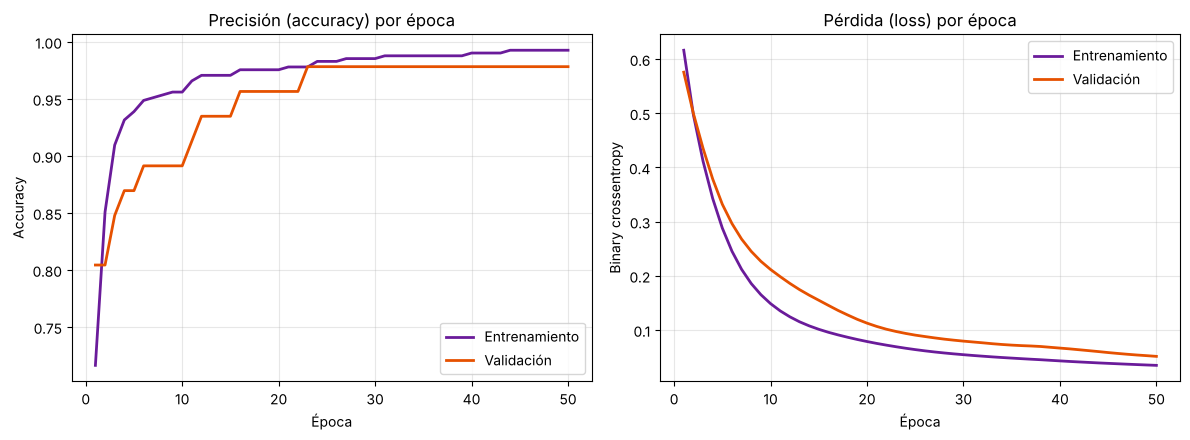

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
epocas = range(1, len(h["loss"]) + 1)

# Precisión
ejes[0].plot(epocas, h["accuracy"],     label="Entrenamiento", color="#6A1B9A", lw=2)
ejes[0].plot(epocas, h["val_accuracy"], label="Validación",    color="#E65100", lw=2)
ejes[0].set_title("Precisión (accuracy) por época")
ejes[0].set_xlabel("Época"); ejes[0].set_ylabel("Accuracy")
ejes[0].legend(); ejes[0].grid(alpha=0.3)

# Pérdida
ejes[1].plot(epocas, h["loss"],     label="Entrenamiento", color="#6A1B9A", lw=2)
ejes[1].plot(epocas, h["val_loss"], label="Validación",    color="#E65100", lw=2)
ejes[1].set_title("Pérdida (loss) por época")
ejes[1].set_xlabel("Época"); ejes[1].set_ylabel("Binary crossentropy")
ejes[1].legend(); ejes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Cómo leer las gráficas
- **Curvas que bajan (pérdida) y suben (precisión):** la red está aprendiendo.
- **Entrenamiento y validación cercanas:** la red generaliza bien.
- **Brecha que crece** (entrenamiento mejora y validación empeora): sobreajuste.
- **Ambas planas y con mal desempeño:** subajuste.

---
## Conclusiones

> Las cifras de abajo corresponden a la ejecución de referencia con semilla 42. En otro entorno (otra versión de TensorFlow o de hardware) pueden variar ligeramente, pero la lectura general se mantiene.

**Resultado en prueba (114 pacientes nunca vistos):** pérdida ≈ **0,085** y precisión ≈ **96,5 %** (110 aciertos de 114).

**Lectura de las curvas:**
- La pérdida de entrenamiento y la de validación bajan juntas durante las 50 épocas. La de validación queda un poco por encima y la brecha es pequeña, sin que la validación empiece a subir: la red **aprendió y generaliza**, sin señales claras de sobreajuste.
- La precisión de entrenamiento sube rápido (≈ 95 % hacia la época 6) y la de validación la alcanza más despacio (≈ 98 % hacia la época 23). Después ambas se estabilizan. La validación usa solo ≈ 46 filas, por eso su curva es escalonada y ruidosa; la cifra confiable es la de prueba.
- La precisión de prueba (96,5 %) es algo menor que la de entrenamiento (≈ 99 %). Una brecha pequeña como esta es normal: los datos de prueba son nuevos para la red.

**Lectura clínica (matriz de confusión):** de 42 tumores malignos, la red detectó 41 (*recall* ≈ 97,6 %) y dejó pasar 1 como benigno. Además marcó 3 benignos como malignos (falsos positivos). En diagnóstico, un falso positivo se resuelve con estudios adicionales, pero un falso negativo retrasa un tratamiento; por eso es relevante que el error más grave sea el menos frecuente.

**Limitaciones y mejoras posibles:**
- Con 114 pacientes de prueba, un solo caso mueve la precisión cerca de 0,9 puntos: una validación cruzada daría una estimación más estable.
- Se podría probar un umbral menor a 0,5 si se quiere priorizar la detección de malignos, aceptando más falsos positivos.
- Ajustes como más/menos neuronas, *dropout* o parada temprana (*early stopping*) podrían probarse, aunque la red actual ya generaliza bien.

**Idea clave:** una red pequeña (641 parámetros), con datos escalados sin fuga de información, alcanza ≈ 96,5 % de precisión en un problema real de diagnóstico, y las curvas de validación permiten comprobar que aprendió en vez de memorizar.

---
## Referencias
- Wolberg, W. H., Street, W. N., & Mangasarian, O. L. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17
- TensorFlow. (s. f.). *The Sequential model*. https://www.tensorflow.org/guide/keras/sequential_model
- scikit-learn developers. (s. f.). *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html